In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/pet-breed-classifier

import torch
print(torch.__version__, '| GPU:', torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/pet-breed-classifier
2.11.0+cu130 | GPU: True


In [ ]:
%%writefile src/models.py
import torch.nn as nn


def conv_block(in_ch, out_ch):
    """Conv -> BatchNorm -> ReLU -> MaxPool: ქსელის განმეორებადი ბლოკი."""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

Writing src/models.py


In [ ]:
%%writefile -a src/models.py


class SimpleCNN(nn.Module):
    """ნულიდან დაწერილი baseline: 4 conv ბლოკი + კლასიფიკატორი."""

    def __init__(self, num_classes=37, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),     # 224 -> 112
            conv_block(32, 64),    # 112 -> 56
            conv_block(64, 128),   # 56  -> 28
            conv_block(128, 256),  # 28  -> 14
        )
        self.pool = nn.AdaptiveAvgPool2d(1)   # 14x14 -> 1x1
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

Appending to src/models.py


In [ ]:
import torch
from src.models import SimpleCNN

model = SimpleCNN(num_classes=37)

# ყალბი batch: 32 სურათი, 3 არხი, 224x224
dummy = torch.randn(32, 3, 224, 224)
out = model(dummy)

print('გამოსასვლელის ფორმა:', out.shape)
print('პარამეტრები:', sum(p.numel() for p in model.parameters()))

გამოსასვლელის ფორმა: torch.Size([32, 37])
პარამეტრები: 398885


In [ ]:
%%writefile src/train.py
import torch
import torch.nn as nn


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)

    return total_loss / total, correct / total

Overwriting src/train.py


In [ ]:
%%writefile -a src/train.py


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss = criterion(out, y)

        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)

    return total_loss / total, correct / total

Appending to src/train.py


In [ ]:
%%writefile -a src/train.py

import time


def fit(model, train_loader, val_loader, epochs, lr, device, ckpt_path,
        weight_decay=1e-4, label_smoothing=0.0, use_wandb=False):
    model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc = evaluate(model, val_loader, criterion, device)
        scheduler.step()

        for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc]):
            history[k].append(v)

        if use_wandb:
            import wandb
            wandb.log({"epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc,
                       "val_loss": va_loss, "val_acc": va_acc,
                       "lr": optimizer.param_groups[0]["lr"]})

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            torch.save(model.state_dict(), ckpt_path)

        print(f"epoch {epoch:02d}/{epochs} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time() - t0:.0f}s")

    print(f"საუკეთესო val acc: {best_val_acc:.3f}")
    return history

Appending to src/train.py


In [ ]:
import torch
from src.data import get_dataloaders
from src.models import SimpleCNN
from src.train import fit

device = 'cuda'
torch.manual_seed(42)

train_loader, val_loader, test_loader, classes = get_dataloaders(
    root='/content/data', batch_size=32, num_workers=0)
model = SimpleCNN(num_classes=37, dropout=0.3)

history = fit(model, train_loader, val_loader,
              epochs=2, lr=1e-3, device=device,
              ckpt_path='models/baseline_cnn.pth')

epoch 01/2 | train loss 3.554 acc 0.061 | val loss 3.521 acc 0.057 | 34s
epoch 02/2 | train loss 3.398 acc 0.098 | val loss 3.461 acc 0.086 | 33s
საუკეთესო val acc: 0.086


In [ ]:
import torch, json
from src.data import get_dataloaders
from src.models import SimpleCNN
from src.train import fit

device = 'cuda'
torch.manual_seed(42)

train_loader, val_loader, test_loader, classes = get_dataloaders(
    root='/content/data', batch_size=32, num_workers=0)
model = SimpleCNN(num_classes=37, dropout=0.3)

history = fit(model, train_loader, val_loader,
              epochs=15, lr=1e-3, device=device,
              ckpt_path='models/baseline_cnn.pth')

with open('reports/baseline_history.json', 'w') as f:
    json.dump(history, f)

epoch 01/15 | train loss 3.554 acc 0.060 | val loss 3.523 acc 0.054 | 33s
epoch 02/15 | train loss 3.421 acc 0.092 | val loss 3.507 acc 0.083 | 32s
epoch 03/15 | train loss 3.351 acc 0.096 | val loss 3.430 acc 0.077 | 32s
epoch 04/15 | train loss 3.277 acc 0.110 | val loss 3.404 acc 0.090 | 32s
epoch 05/15 | train loss 3.187 acc 0.136 | val loss 3.436 acc 0.101 | 32s
epoch 06/15 | train loss 3.086 acc 0.163 | val loss 3.235 acc 0.114 | 32s
epoch 07/15 | train loss 3.041 acc 0.167 | val loss 3.212 acc 0.124 | 32s
epoch 08/15 | train loss 2.941 acc 0.189 | val loss 3.049 acc 0.175 | 32s
epoch 09/15 | train loss 2.868 acc 0.201 | val loss 3.108 acc 0.163 | 32s
epoch 10/15 | train loss 2.823 acc 0.222 | val loss 3.158 acc 0.151 | 32s
epoch 11/15 | train loss 2.745 acc 0.241 | val loss 2.937 acc 0.202 | 32s
epoch 12/15 | train loss 2.700 acc 0.249 | val loss 2.855 acc 0.217 | 32s
epoch 13/15 | train loss 2.659 acc 0.267 | val loss 2.827 acc 0.224 | 32s
epoch 14/15 | train loss 2.641 acc 0.2

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/pet-breed-classifier

import json
with open('reports/baseline_history.json') as f:
    history = json.load(f)

print('ეპოქები:', len(history['train_loss']))
print('საუკეთესო val acc:', max(history['val_acc']))

Mounted at /content/drive
/content/drive/MyDrive/pet-breed-classifier
ეპოქები: 15
საუკეთესო val acc: 0.24048913043478262


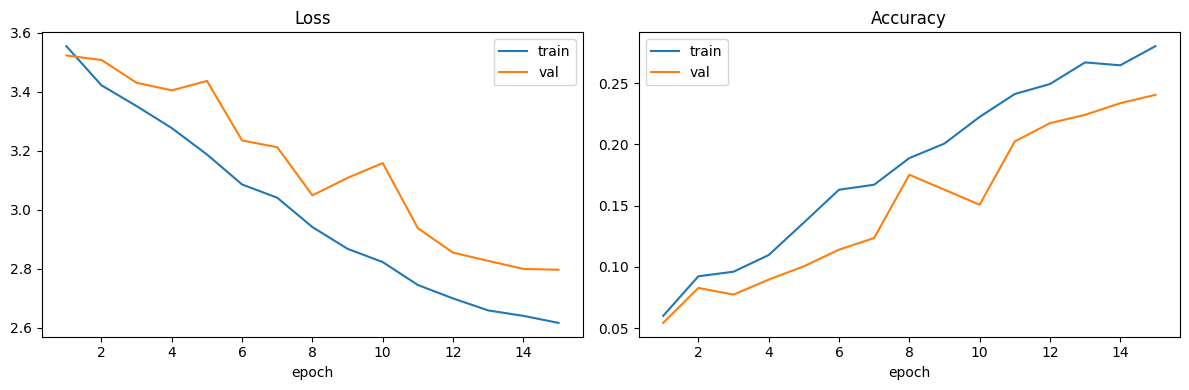

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(history['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history['train_loss'], label='train')
ax[0].plot(epochs, history['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()

ax[1].plot(epochs, history['train_acc'], label='train')
ax[1].plot(epochs, history['val_acc'], label='val')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()

plt.tight_layout()
plt.savefig('reports/figures/baseline_curves.png', dpi=150)
plt.show()